### Setup, Random Seed (770) & Label Definitions


In [1]:
import hashlib
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import TensorDataset
from IPython.display import display

SEED = 770
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ACCEPTABLE = 0
DEFECTIVE = 1
LABEL_MAP = {"ok_front": ACCEPTABLE, "def_front": DEFECTIVE}
CLASS_NAMES = {ACCEPTABLE: "acceptable", DEFECTIVE: "defective"}

DATA_DIR = Path(os.environ.get("CASTING_DATA_DIR", "casting_512x512"))


def find_class_dir(base_dir: Path, name: str) -> Path:
    matches = sorted(
        p for p in base_dir.rglob(name)
        if p.is_dir() and "casting_data" not in {part.lower() for part in p.parts}
    )
    if not matches:
        raise FileNotFoundError(f"Missing '{name}' under '{base_dir.name}'.")
    return matches[0]


ok_dir = find_class_dir(DATA_DIR, "ok_front")
def_dir = find_class_dir(DATA_DIR, "def_front")
print(f"Labels: defective = {DEFECTIVE}, acceptable = {ACCEPTABLE} | Random seed = {SEED}")


Labels: defective = 1, acceptable = 0 | Random seed = 770


### Data Audit: Dimensions, Class Counts & Exclusions


In [2]:
records, unreadable = [], []

for folder_name, folder_path in [("ok_front", ok_dir), ("def_front", def_dir)]:
    label = LABEL_MAP[folder_name]
    for p in sorted(folder_path.iterdir()):
        if not p.is_file():
            continue
        rel_path = f"{folder_name}/{p.name}"
        try:
            with Image.open(p) as im:
                im.load()
                dims = f"{im.size[0]} x {im.size[1]}"
                arr = np.asarray(im)
                pix_hash = hashlib.sha256(arr.tobytes() + str(arr.shape).encode()).hexdigest()
            records.append(
                {
                    "label": label,
                    "class": CLASS_NAMES[label],
                    "filename": p.name,
                    "rel_path": rel_path,
                    "path": p,
                    "dimensions": dims,
                    "pixel_sha256": pix_hash,
                }
            )
        except Exception as exc:
            unreadable.append(f"{rel_path} ({type(exc).__name__})")

raw_df = pd.DataFrame(records).sort_values(["label", "filename"]).reset_index(drop=True)

kept_idx, same_label_dups, conflicting_dups = [], [], []
for _, grp in raw_df.groupby("pixel_sha256", sort=False):
    grp_sorted = grp.sort_values(["label", "filename"])
    if grp_sorted["label"].nunique() > 1:
        conflicting_dups.extend(grp_sorted["rel_path"].tolist())
    else:
        kept_idx.append(grp_sorted.index[0])
        same_label_dups.extend(grp_sorted["rel_path"].iloc[1:].tolist())

cleaned_df = raw_df.loc[kept_idx].sort_values(["label", "filename"]).reset_index(drop=True)

audit_df = pd.DataFrame(
    [
        {
            "Class": f"{CLASS_NAMES[lbl]} ({lbl})",
            "Count": int((cleaned_df["label"] == lbl).sum()),
            "Dimensions": ", ".join(sorted(cleaned_df.loc[cleaned_df["label"] == lbl, "dimensions"].unique())),
        }
        for lbl in [ACCEPTABLE, DEFECTIVE]
    ]
    + [
        {
            "Class": "Total",
            "Count": len(cleaned_df),
            "Dimensions": ", ".join(sorted(cleaned_df["dimensions"].unique())),
        }
    ]
)
display(audit_df)

total_excluded = len(unreadable) + len(same_label_dups) + len(conflicting_dups)
print(
    f"Exclusions -> unreadable: {len(unreadable)}, same-label duplicates: {len(same_label_dups)}, "
    f"conflicting-label duplicates: {len(conflicting_dups)}, total excluded: {total_excluded}."
)
if unreadable:
    print("Unreadable:", unreadable)
if same_label_dups:
    print("Excluded same-label duplicates:", same_label_dups)
if conflicting_dups:
    print("Set-aside conflicting-label duplicates:", conflicting_dups)


,Class,Count,Dimensions
0,acceptable (0),519,512 x 512
1,defective (1),781,512 x 512
2,Total,1300,512 x 512


Exclusions -> unreadable: 0, same-label duplicates: 0, conflicting-label duplicates: 0, total excluded: 0.


### Labeled Grid of 8 Sample Images


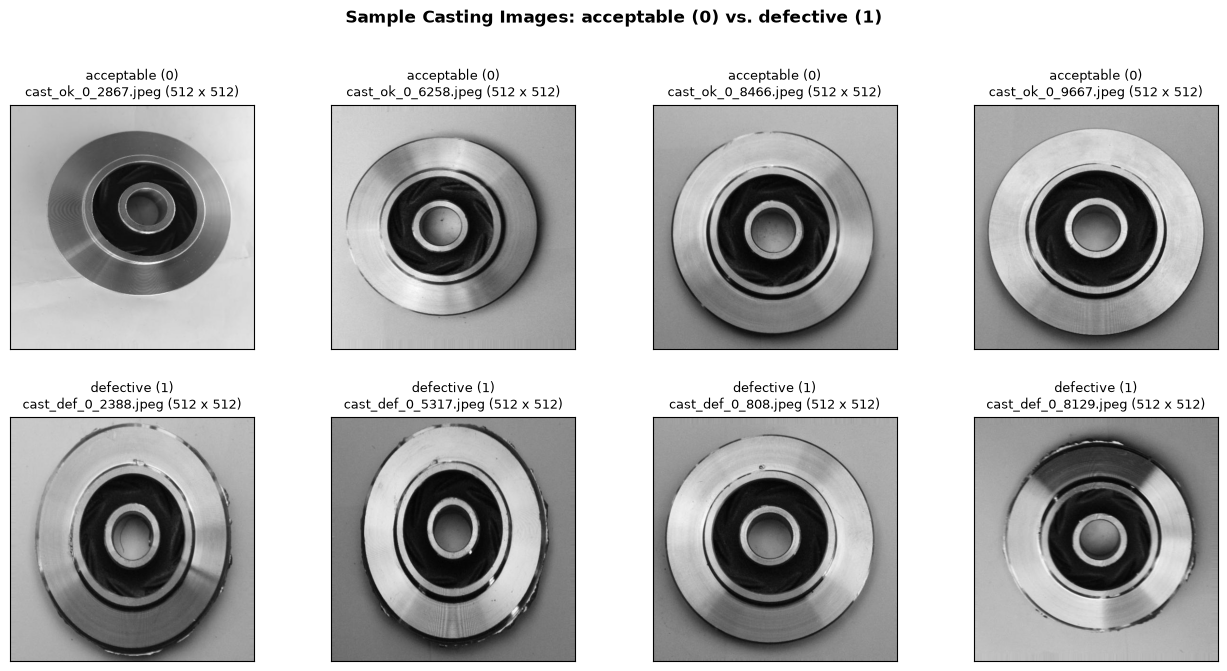

In [3]:
rng = np.random.default_rng(SEED)
sample_rows = []
for lbl in [ACCEPTABLE, DEFECTIVE]:
    idx = sorted(rng.choice(cleaned_df[cleaned_df["label"] == lbl].index.to_numpy(), size=4, replace=False))
    sample_rows.extend(cleaned_df.loc[i] for i in idx)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.8))
for ax, row in zip(axes.flat, sample_rows):
    with Image.open(row["path"]) as im:
        ax.imshow(im)
    ax.set_title(f"{row['class']} ({row['label']})\n{row['filename']} ({row['dimensions']})", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Sample Casting Images: acceptable (0) vs. defective (1)", fontsize=12, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.subplots_adjust(hspace=0.28)
plt.show()


### Stratified Train / Validation / Test Split (70% / 15% / 15%, Seed 770)


In [4]:
train_df, temp_df = train_test_split(
    cleaned_df, test_size=0.30, stratify=cleaned_df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)
train_df, val_df, test_df = (
    train_df.reset_index(drop=True),
    val_df.reset_index(drop=True),
    test_df.reset_index(drop=True),
)

splits = [("Train", train_df), ("Validation", val_df), ("Test", test_df)]
split_table = pd.DataFrame(
    [
        {
            "Split": name,
            "Total": len(df_s),
            "Share": f"{100.0 * len(df_s) / len(cleaned_df):.1f}%",
            "acceptable (0)": int((df_s["label"] == ACCEPTABLE).sum()),
            "defective (1)": int((df_s["label"] == DEFECTIVE).sum()),
        }
        for name, df_s in splits
    ]
)
display(split_table)

for name, df_s in splits:
    files = sorted(df_s["rel_path"].tolist())
    print(f"\n{name.upper()} ({len(files)} images):")
    for i in range(0, len(files), 5):
        print("  " + "  ".join(f"{f:<30}" for f in files[i : i + 5]).rstrip())


,Split,Total,Share,acceptable (0),defective (1)
0,Train,910,70.0%,363,547
1,Validation,195,15.0%,78,117
2,Test,195,15.0%,78,117



TRAIN (910 images):
  def_front/cast_def_0_0.jpeg     def_front/cast_def_0_1015.jpeg  def_front/cast_def_0_102.jpeg   def_front/cast_def_0_1053.jpeg  def_front/cast_def_0_1055.jpeg
  def_front/cast_def_0_1087.jpeg  def_front/cast_def_0_1091.jpeg  def_front/cast_def_0_1112.jpeg  def_front/cast_def_0_1115.jpeg  def_front/cast_def_0_1123.jpeg
  def_front/cast_def_0_1137.jpeg  def_front/cast_def_0_1139.jpeg  def_front/cast_def_0_1145.jpeg  def_front/cast_def_0_1147.jpeg  def_front/cast_def_0_1155.jpeg
  def_front/cast_def_0_1157.jpeg  def_front/cast_def_0_1187.jpeg  def_front/cast_def_0_1188.jpeg  def_front/cast_def_0_1225.jpeg  def_front/cast_def_0_1226.jpeg
  def_front/cast_def_0_1257.jpeg  def_front/cast_def_0_1261.jpeg  def_front/cast_def_0_127.jpeg   def_front/cast_def_0_1283.jpeg  def_front/cast_def_0_1286.jpeg
  def_front/cast_def_0_1359.jpeg  def_front/cast_def_0_1381.jpeg  def_front/cast_def_0_1411.jpeg  def_front/cast_def_0_1427.jpeg  def_front/cast_def_0_1432.jpeg
  def_front/c

### Grayscale 64 x 64 Preprocessing Scaled to [0, 1]


In [5]:
IMG_SIZE = (64, 64)


def preprocess_image(path: Path) -> np.ndarray:
    with Image.open(path) as im:
        gray = im.convert("L").resize(IMG_SIZE, Image.Resampling.BILINEAR)
        return np.asarray(gray, dtype=np.float32) / 255.0


def build_arrays(df_s: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    X = np.stack([preprocess_image(p) for p in df_s["path"]], axis=0)
    y = df_s["label"].to_numpy(dtype=np.int64, copy=True)
    return X, y


X_train, y_train = build_arrays(train_df)
X_val, y_val = build_arrays(val_df)
X_test, y_test = build_arrays(test_df)

X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

train_dataset = TensorDataset(torch.from_numpy(X_train).unsqueeze(1), torch.from_numpy(y_train))
val_dataset = TensorDataset(torch.from_numpy(X_val).unsqueeze(1), torch.from_numpy(y_val))
test_dataset = TensorDataset(torch.from_numpy(X_test).unsqueeze(1), torch.from_numpy(y_test))

prep_table = pd.DataFrame(
    [
        {
            "Split": name,
            "Image": str(X.shape),
            "Flat": str(X_flat.shape),
            "Tensor": str(tuple(ds.tensors[0].shape)),
            "Dtype": str(X.dtype),
            "Min": f"{X.min():.4f}",
            "Max": f"{X.max():.4f}",
        }
        for name, X, X_flat, ds in [
            ("Train", X_train, X_train_flat, train_dataset),
            ("Validation", X_val, X_val_flat, val_dataset),
            ("Test", X_test, X_test_flat, test_dataset),
        ]
    ]
)
display(prep_table)


,Split,Image,Flat,Tensor,Dtype,Min,Max
0,Train,"(910, 64, 64)","(910, 4096)","(910, 1, 64, 64)",float32,0.0235,1.0000
1,Validation,"(195, 64, 64)","(195, 4096)","(195, 1, 64, 64)",float32,0.0235,1.0000
2,Test,"(195, 64, 64)","(195, 4096)","(195, 1, 64, 64)",float32,0.0275,1.0000
